# Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance

**Nama:** Fauzan Tamma Harish Kunfaza  |  **NRP:** 5054251035

## Tujuan
1. Menerapkan *ensemble method* (Random Forest) untuk klasifikasi.
2. Menangani *class imbalance* dengan *cost-sensitive learning* (`class_weight`), *oversampling* (SMOTE), dan *undersampling*.
3. Mengevaluasi model dengan metrik yang sesuai untuk data tidak seimbang: precision, recall, F1-score, ROC-AUC (ditambah PR-AUC), dan confusion matrix.

## Dataset
*Credit Card Fraud Detection* (Kaggle, `mlg-ulb/creditcardfraud`): transaksi kartu kredit pemegang kartu di Eropa selama dua hari. Target `Class`: **0 = transaksi normal**, **1 = fraud**.

## Alur pengerjaan
Load data → cek distribusi kelas → split 80:20 (stratify) → resampling **hanya pada data latih** → latih 4 model Random Forest → evaluasi pada data uji asli → analisis.

## 1. Import dan Load Data
Dataset dibaca dengan pandas, lalu dilihat struktur, ukuran, dan tipe datanya.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("creditcard.csv")
print(df.shape)
df.info()

(284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     

In [ ]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
#pemeriksaan kualitas data
print("Missing value :", df.isnull().sum().sum())
print("Baris duplikat:", df.duplicated().sum(), "(fraud di antaranya:", df[df.duplicated()]["Class"].sum(), ")")
df[["Time", "Amount"]].describe().round(2)

Missing value : 0
Baris duplikat: 1081 (fraud di antaranya: 19 )


,Time,Amount
count,284807.00,284807.00
mean,94813.86,88.35
std,47488.15,250.12
min,0.00,0.00
25%,54201.50,5.60
50%,84692.00,22.00
75%,139320.50,77.16
max,172792.00,25691.16


**Observasi data**
- Dataset berukuran **284.807 baris × 31 kolom**; seluruh kolom numerik dan **tidak ada missing value**.
- `V1`–`V28` adalah hasil transformasi PCA (nama dan makna aslinya dirahasiakan demi privasi), sehingga skalanya sudah relatif seragam. `Time` (detik sejak transaksi pertama) dan `Amount` (nominal) adalah fitur asli. `Class` adalah target.
- Terdapat 1.081 baris duplikat (19 di antaranya fraud). Baris ini **tidak dihapus** agar distribusi data tetap sesuai aslinya.
- `Amount` sangat miring ke kanan (rata-rata ≈ 88, median 22, maksimum 25.691).

## 2. Distribusi Kelas dan Pembagian Data
Langkah pertama praproses adalah mengukur seberapa tidak seimbang kelas target. Sumbu-y memakai skala log agar batang kelas fraud tetap terlihat.

Class
0    284315
1       492
Name: count, dtype: int64 Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


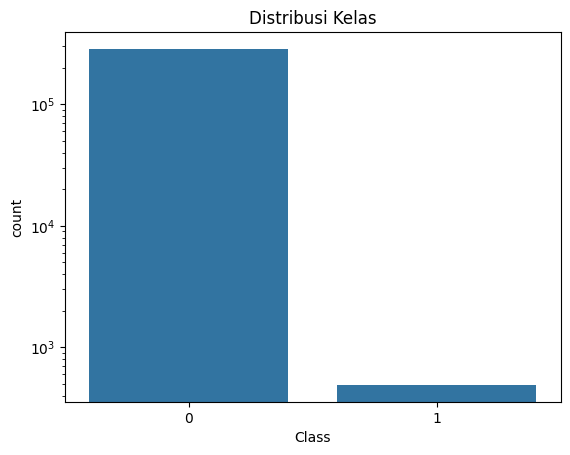

In [4]:
counts = df["Class"].value_counts()
persen = df["Class"].value_counts(normalize=True) * 100
print(counts, persen)

sns.countplot(x="Class", data=df)
plt.yscale("log")   # skala log supaya batang fraud tetap terlihat
plt.title("Distribusi Kelas")
plt.show()

**Interpretasi:** dari 284.807 transaksi, hanya **492 (0,17%)** yang fraud, sedangkan **284.315 (99,83%)** normal. Rasionya sekitar **1 : 578**. Ini kasus *class imbalance* yang ekstrem. Tanpa penanganan, model cenderung condong ke kelas mayoritas karena kesalahan pada kelas fraud hampir tidak berpengaruh pada rata-rata kesalahan keseluruhan.

### Split data latih dan uji (80:20, stratified)
`stratify=y` menjaga proporsi fraud tetap sama di data latih dan data uji. Tanpa ini, data uji yang hanya berisi ~100 fraud bisa saja mendapat jauh lebih sedikit atau lebih banyak fraud secara kebetulan.

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [6]:
print("Data latih:", X_train.shape, "| fraud:", y_train.sum(), f"({y_train.mean()*100:.3f}%)")
print("Data uji  :", X_test.shape,  "| fraud:", y_test.sum(),  f"({y_test.mean()*100:.3f}%)")

Data latih: (227845, 30) | fraud: 394 (0.173%)
Data uji  : (56962, 30) | fraud: 98 (0.172%)


Data latih berisi 227.845 transaksi (394 fraud) dan data uji 56.962 transaksi (**hanya 98 fraud**). Jumlah fraud di data uji yang kecil berarti metrik kelas fraud cukup sensitif: selisih satu transaksi saja menggeser recall sekitar 1 poin persentase.

Fitur **tidak di-scaling** karena Random Forest berbasis pohon keputusan yang hanya melihat urutan nilai fitur, bukan skalanya.

### Mengapa accuracy saja tidak cukup?
Sebagai pembanding, dibuat model "bodoh" yang **selalu menebak transaksi normal**.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_dummy = dummy.predict(X_test)

print("Akurasi model dummy      :", round(accuracy_score(y_test, y_dummy), 4))
print("Recall fraud model dummy :", recall_score(y_test, y_dummy))

Akurasi model dummy      : 0.9983
Recall fraud model dummy : 0.0


Model dummy meraih **akurasi ≈ 99,83%** tetapi **recall fraud = 0**: tidak satu pun penipuan terdeteksi. Jadi pada data ini akurasi hampir tidak mengukur kemampuan mendeteksi fraud, karena didominasi kelas normal. Evaluasi harus berfokus pada **precision, recall, F1, dan AUC untuk kelas fraud**.

## 3. Penanganan Class Imbalance
Tiga pendekatan dibandingkan dengan model tanpa penanganan (baseline):

| Pendekatan | Cara kerja | Catatan |
|---|---|---|
| **Cost-sensitive** (`class_weight="balanced_subsample"`) | Kesalahan pada kelas fraud diberi bobot lebih besar saat pohon dibangun | Data tidak diubah |
| **SMOTE** (oversampling) | Membuat sampel fraud sintetis lewat interpolasi antar tetangga terdekat | Data latih membesar |
| **Random undersampling** | Membuang sebagian besar sampel normal sampai jumlahnya sama dengan fraud | Banyak informasi kelas normal hilang |

> **Penting:** resampling dilakukan **hanya pada data latih** (setelah split). Data uji dibiarkan dengan distribusi asli supaya evaluasi mencerminkan kondisi nyata dan tidak terjadi *data leakage* (sampel sintetis yang "meniru" data uji tidak boleh masuk ke proses latih).

In [8]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
X_us, y_us = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)

print(y_sm.value_counts(), y_us.value_counts())

Class
0    227451
1    227451
Name: count, dtype: int64 Class
0    394
1    394
Name: count, dtype: int64


Setelah resampling, data latih seimbang 50:50: SMOTE menghasilkan **227.451 normal : 227.451 fraud** (ukuran data bertambah ±2×), sedangkan undersampling menghasilkan **394 : 394** (data menyusut drastis).

## 4. Membangun Model Ensemble (Random Forest)
Random Forest dipilih karena menggabungkan banyak pohon keputusan (*bagging*) sehingga lebih stabil dan tahan *overfitting* dibanding satu pohon, serta bekerja baik pada data tabular tanpa perlu scaling. Empat model dilatih dengan hyperparameter yang sama (`n_estimators=100`, `random_state=42`) sehingga **perbedaan hasil hanya berasal dari cara penanganan imbalance**.

1. **RF Baseline**: data latih asli, tanpa penanganan.
2. **RF class_weight**: data latih asli, tetapi kelas fraud diberi bobot lebih besar.
3. **RF + SMOTE**: dilatih pada data hasil SMOTE.
4. **RF + Undersample**: dilatih pada data hasil undersampling.

In [9]:
from sklearn.ensemble import RandomForestClassifier

def rf(**kw):
    return RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42, **kw)

models = {
    "RF Baseline":      (rf(),                                  X_train, y_train),
    "RF class_weight":  (rf(class_weight="balanced_subsample"), X_train, y_train),
    "RF + SMOTE":       (rf(),                                  X_sm,    y_sm),
    "RF + Undersample": (rf(),                                  X_us,    y_us),
}

for name, (m, Xt, yt) in models.items():
    m.fit(Xt, yt)

## 5. Evaluasi Model
Semua model dievaluasi pada **data uji asli** (56.962 transaksi, 98 fraud) dengan kelas fraud sebagai kelas positif.

- **Precision**: dari transaksi yang diprediksi fraud, berapa yang benar-benar fraud (ukuran *false alarm*).
- **Recall**: dari seluruh fraud, berapa yang berhasil terdeteksi (ukuran fraud yang lolos).
- **F1-score**: rata-rata harmonik precision dan recall.
- **ROC-AUC**: kemampuan memisahkan kedua kelas di semua threshold; cenderung optimistis pada data sangat tidak seimbang.
- **PR-AUC** (*average precision*): ringkasan kurva precision-recall; lebih peka terhadap performa pada kelas minoritas.

In [10]:
from sklearn.metrics import (precision_recall_fscore_support, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay)

hasil = []
for name, (m, _, _) in models.items():
    y_pred = m.predict(X_test)
    y_prob = m.predict_proba(X_test)[:, 1]      # AUC butuh probabilitas
    p, r, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, pos_label=1, average="binary")
    hasil.append({"Model": name, "Precision": p, "Recall": r, "F1": f1,
                  "ROC-AUC": roc_auc_score(y_test, y_prob),
                  "PR-AUC": average_precision_score(y_test, y_prob)})

tabel = pd.DataFrame(hasil).set_index("Model").round(4)
tabel

,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,
RF Baseline,0.9412,0.8163,0.8743,0.9630,0.8734
RF class_weight,0.9600,0.7347,0.8324,0.9529,0.8597
RF + SMOTE,0.8351,0.8265,0.8308,0.9644,0.8747
RF + Undersample,0.0423,0.9184,0.0809,0.9777,0.6953


### Confusion matrix

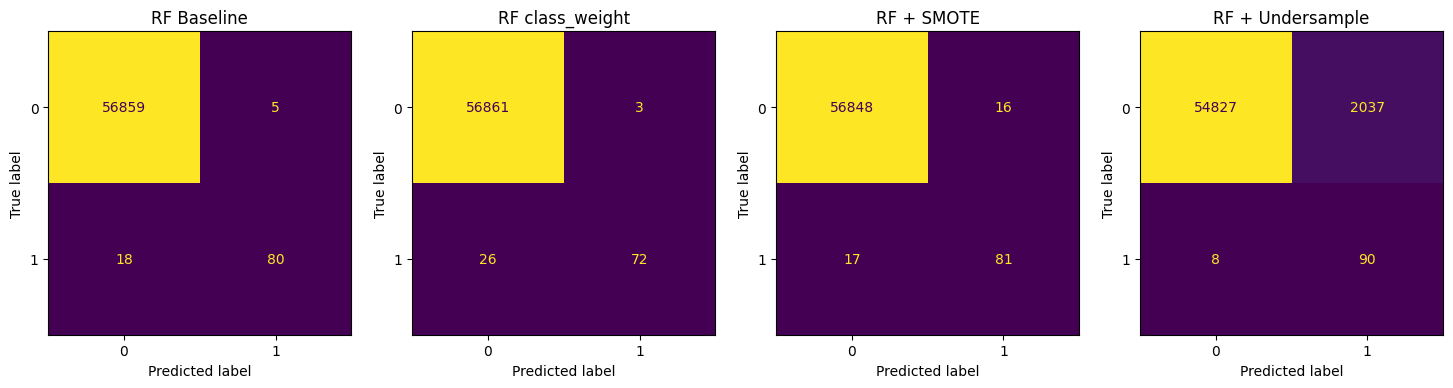

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, (m, _, _)) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.show()

Rincian confusion matrix (data uji: 56.864 normal dan 98 fraud):

| Model | TN | FP | FN | TP |
|---|---:|---:|---:|---:|
| RF Baseline | 56.859 | 5 | 18 | 80 |
| RF class_weight | 56.861 | 3 | 26 | 72 |
| RF + SMOTE | 56.848 | 16 | 17 | 81 |
| RF + Undersample | 54.827 | 2.037 | 8 | 90 |

In [12]:
# Akurasi dibandingkan recall fraud (termasuk model dummy "selalu normal")
rows = []
for name, (m, _, _) in models.items():
    yp = m.predict(X_test)
    rows.append({"Model": name, "Akurasi": accuracy_score(y_test, yp), "Recall fraud": recall_score(y_test, yp)})
rows.append({"Model": "Dummy (selalu normal)", "Akurasi": accuracy_score(y_test, y_dummy), "Recall fraud": recall_score(y_test, y_dummy)})
pd.DataFrame(rows).set_index("Model").round(4)

,Akurasi,Recall fraud
Model,,
RF Baseline,0.9996,0.8163
RF class_weight,0.9995,0.7347
RF + SMOTE,0.9994,0.8265
RF + Undersample,0.9641,0.9184
Dummy (selalu normal),0.9983,0.0000


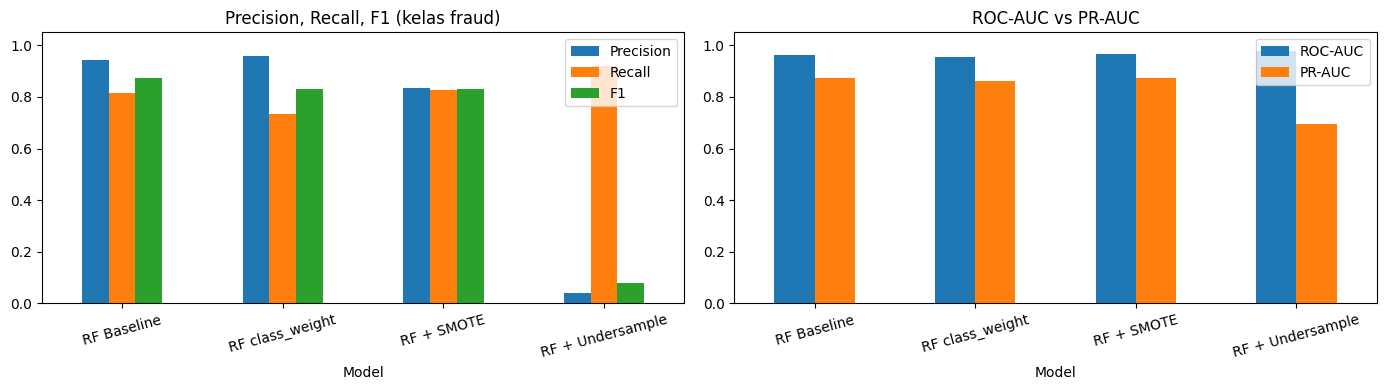

In [13]:
# Visualisasi perbandingan metrik
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
tabel[["Precision", "Recall", "F1"]].plot(kind="bar", ax=axes[0], rot=15)
axes[0].set_title("Precision, Recall, F1 (kelas fraud)")
axes[0].set_ylim(0, 1.05)
tabel[["ROC-AUC", "PR-AUC"]].plot(kind="bar", ax=axes[1], rot=15)
axes[1].set_title("ROC-AUC vs PR-AUC")
axes[1].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

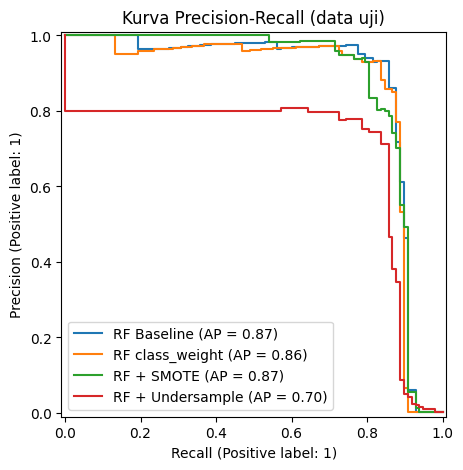

In [14]:
# Kurva Precision-Recall seluruh model pada data uji
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 5))
for name, (m, _, _) in models.items():
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, ax=ax, name=name)
ax.set_title("Kurva Precision-Recall (data uji)")
plt.show()

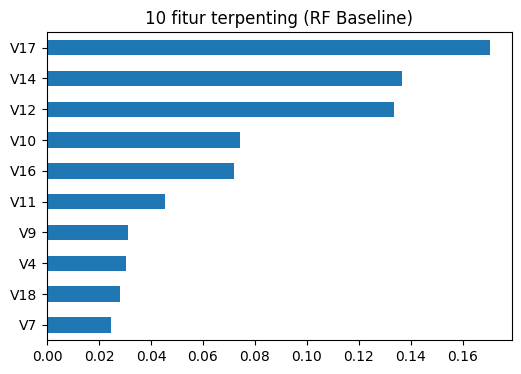

In [15]:
# Fitur terpenting menurut RF Baseline
imp = pd.Series(models["RF Baseline"][0].feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp[::-1].plot(kind="barh", figsize=(6, 4), title="10 fitur terpenting (RF Baseline)")
plt.show()

## 6. Analisis Hasil

**Ringkasan metrik (kelas fraud, data uji)**

| Model | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|
| RF Baseline | 0,9412 | 0,8163 | **0,8743** | 0,9630 | 0,8734 |
| RF class_weight | **0,9600** | 0,7347 | 0,8324 | 0,9529 | 0,8597 |
| RF + SMOTE | 0,8351 | 0,8265 | 0,8308 | 0,9644 | **0,8747** |
| RF + Undersample | 0,0423 | **0,9184** | 0,0809 | **0,9777** | 0,6953 |

**1. Baseline sudah kuat.** Tanpa penanganan apa pun, Random Forest mendeteksi 80 dari 98 fraud dengan hanya 5 *false positive* (F1 tertinggi, 0,8743). Penanganan imbalance tidak otomatis memperbaiki hasil.

**2. class_weight: paling "hati-hati".** Precision tertinggi (0,96; hanya 3 false positive) tetapi recall terendah (0,7347; 26 fraud lolos). Model lebih jarang menandai fraud, sehingga *false alarm* sedikit namun lebih banyak penipuan terlewat.

**3. SMOTE: recall naik tipis, precision turun.** Recall naik dari 0,8163 menjadi 0,8265 (hanya **1 fraud tambahan** tertangkap), sementara false positive naik dari 5 menjadi 16. Hasilnya F1 (0,8308) justru lebih rendah dari baseline. ROC-AUC dan PR-AUC SMOTE sedikit lebih tinggi dari baseline, tetapi selisihnya sangat kecil (0,0014 untuk ROC-AUC dan 0,0013 untuk PR-AUC) sehingga belum tentu bermakna. Penyebab yang masuk akal: dengan hanya 394 fraud di data latih, sampel sintetis hasil interpolasi dapat jatuh di wilayah yang beririsan dengan transaksi normal, sehingga batas keputusan bergeser dan false positive bertambah.

**4. Undersampling: recall tertinggi, tetapi tidak praktis.** Hanya 8 fraud yang lolos (recall 0,9184), namun **2.037 transaksi normal ikut ditandai fraud**; dari 2.127 transaksi yang diprediksi fraud, hanya 90 yang benar (precision 0,0423). Model hanya melihat 394 contoh normal saat latih, sehingga tidak mengenali keragaman transaksi normal. Selain itu model dilatih pada proporsi 50:50 sedangkan data uji 99,8% normal, sehingga threshold 0,5 menjadi terlalu longgar.

**5. ROC-AUC bisa menyesatkan.** Undersampling punya ROC-AUC tertinggi (0,9777) tetapi PR-AUC terendah (0,6953). ROC-AUC memakai *false positive rate* (2.037 / 56.864 ≈ 3,6%) yang terlihat kecil karena jumlah transaksi normal sangat besar, sedangkan precision dan PR-AUC langsung menunjukkan bahwa sebagian besar peringatan adalah alarm palsu. Untuk data tidak seimbang, PR-AUC dan F1 lebih jujur daripada ROC-AUC.

**6. Akurasi menyesatkan.** Model dummy yang tidak mendeteksi satu fraud pun mendapat akurasi 0,9983, lebih tinggi daripada RF + Undersample (0,9641) yang justru menangkap 92% fraud. Selisih akurasi antar tiga model teratas hanya sekitar 0,01% sehingga perbedaan kualitas sebenarnya tidak terlihat. Karena itu akurasi tidak boleh dijadikan acuan.

**7. Pemilihan model bergantung pada biaya kesalahan.**
- Bila ingin keseimbangan terbaik antara fraud tertangkap dan alarm palsu: **RF Baseline** (F1 tertinggi).
- Bila fraud yang lolos jauh lebih mahal dan tersedia tim peninjau manual yang mampu menangani alarm tambahan: **RF + SMOTE** (recall tertinggi di antara model dengan precision yang masih wajar).
- Bila gangguan terhadap pelanggan sah harus diminimalkan: **RF class_weight**.
- **RF + Undersample** tidak layak dipakai dengan threshold bawaan.

## 7. Kesimpulan dan Keterbatasan
- Dataset sangat tidak seimbang (fraud 0,17%), sehingga akurasi tidak informatif dan evaluasi harus memakai precision, recall, F1, serta PR-AUC.
- Random Forest tanpa penanganan imbalance sudah memberi F1 terbaik (0,8743). SMOTE dan `class_weight` hanya menggeser *trade-off* precision-recall, bukan meningkatkan kualitas secara jelas, sedangkan undersampling sangat menurunkan precision.
- **Keterbatasan:** (1) data uji hanya memuat 98 fraud dan evaluasi memakai satu kali split, sehingga selisih kecil antar model (misalnya baseline vs SMOTE) belum tentu signifikan; *stratified cross-validation* akan memberi estimasi yang lebih stabil. (2) Threshold klasifikasi tetap 0,5; penyetelan threshold berdasarkan kurva precision-recall dapat memperbaiki trade-off, terutama untuk model undersampling. (3) Sebanyak 344 baris data uji identik dengan baris di data latih (akibat duplikat pada dataset asli); dampaknya kemungkinan kecil (<1% data uji), tetapi perlu diketahui. (4) Hyperparameter Random Forest tidak di-tuning, dan model boosting (XGBoost/LightGBM) belum dibandingkan.